# Scenario 27: Gym Membership Management and Fitness Activity Analysis System
### Project-Based Assessment - Academic Year 2026 - 27 (ODD)
**Student Name:** V. Dharshan  
**Register Number:** 732925ITR027  
**Class:** 25IT3A  
**Institution:** Velalar College of Engineering and Technology, Erode - 12  
**Department:** Department of Information Technology  
**Course:** 25ITC31 - Foundations of Data Science  

---
## 1. Introduction & Objectives
In modern fitness centres, manual recordkeeping often causes friction in monitoring active memberships, tracking peak attendance hours, analyzing revenue from plans, and evaluating trainer client allocation. 

This notebook demonstrates end-to-end data science techniques:
1. **Database Extraction:** Connecting to the SQLite database and retrieving relational tables into Pandas DataFrames.
2. **Data Wrangling:** Merging attendance, membership plans, and trainer assignments.
3. **Data Cleaning & Transformation:** Imputing missing values, datetime conversions, IQR outlier analysis, and feature engineering.
4. **Exploratory Data Analysis (EDA) & Visualization:** Using Matplotlib and Seaborn to discover meaningful behavioral patterns in gym participation.

## 2. Environment Setup & Library Imports (Unit 1 & Unit 2)

In [1]:
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

DB_PATH = os.path.join('..', 'database', 'gym.db')
print(f"Database exists: {os.path.exists(DB_PATH)}")

Database exists: True


## 3. Database Retrieval (Unit 2 & Unit 3)

In [2]:
conn = sqlite3.connect(DB_PATH)

# Load core tables
members_df = pd.read_sql_query("SELECT * FROM members", conn)
plans_df = pd.read_sql_query("SELECT * FROM membership_plans", conn)
trainers_df = pd.read_sql_query("SELECT * FROM trainers", conn)
subscriptions_df = pd.read_sql_query("SELECT * FROM member_subscriptions", conn)
assignments_df = pd.read_sql_query("SELECT * FROM trainer_assignments", conn)
attendance_df = pd.read_sql_query("SELECT * FROM attendance", conn)

conn.close()

print(f"Members: {members_df.shape}")
print(f"Plans: {plans_df.shape}")
print(f"Trainers: {trainers_df.shape}")
print(f"Subscriptions: {subscriptions_df.shape}")
print(f"Trainer Assignments: {assignments_df.shape}")
print(f"Attendance Records: {attendance_df.shape}")

Members: (20, 8)
Plans: (5, 5)
Trainers: (5, 7)
Subscriptions: (20, 7)
Trainer Assignments: (13, 6)
Attendance Records: (62, 6)


## 4. Data Cleaning, Transformation & Preprocessing (Unit 3 & Unit 4)
- Detecting and removing duplicate rows
- Datetime parsing & duration calculation
- Outlier detection via Interquartile Range (IQR)
- Feature engineering: `day_of_week`, `check_in_hour`, `time_slot`, `age_group`

In [3]:
# 1. Clean Attendance Data
attendance_df['attendance_date'] = pd.to_datetime(attendance_df['attendance_date'])
attendance_df['day_of_week'] = attendance_df['attendance_date'].dt.day_name()

# Calculate workout duration
check_in_dt = pd.to_datetime(attendance_df['attendance_date'].dt.strftime('%Y-%m-%d') + ' ' + attendance_df['check_in_time'])
check_out_dt = pd.to_datetime(attendance_df['attendance_date'].dt.strftime('%Y-%m-%d') + ' ' + attendance_df['check_out_time'])
attendance_df['workout_duration_min'] = (check_out_dt - check_in_dt).dt.total_seconds() / 60.0

# Extract hour of day and time slot
attendance_df['check_in_hour'] = pd.to_datetime(attendance_df['check_in_time'], format='%H:%M:%S').dt.hour
attendance_df['time_slot'] = np.where(attendance_df['check_in_hour'] < 12, 'Morning Shift', 'Evening Shift')

# 2. Clean and Categorize Members Demographics
Q1 = members_df['age'].quantile(0.25)
Q3 = members_df['age'].quantile(0.75)
IQR = Q3 - Q1
print(f"Member Age Statistics: Mean={members_df['age'].mean():.2f}, Median={members_df['age'].median():.2f}, IQR={IQR:.2f}")

bins = [13, 22, 35, 50, 100]
labels = ['Youth (14-22)', 'Young Adult (23-35)', 'Adult (36-50)', 'Senior (51+)']
members_df['age_group'] = pd.cut(members_df['age'], bins=bins, labels=labels)

attendance_df.head()

Member Age Statistics: Mean=29.30, Median=27.00, IQR=9.50


,attendance_id,member_id,attendance_date,check_in_time,check_out_time,workout_type,day_of_week,workout_duration_min,check_in_hour,time_slot
0,1,1,2026-11-01,06:15:00,07:45:00,Weight Training,Sunday,90.0,6,Morning Shift
1,2,3,2026-11-01,06:30:00,08:00:00,Weight Training,Sunday,90.0,6,Morning Shift
2,3,5,2026-11-01,07:00:00,08:15:00,CrossFit,Sunday,75.0,7,Morning Shift
3,4,7,2026-11-01,07:15:00,08:30:00,Weight Training,Sunday,75.0,7,Morning Shift
4,5,2,2026-11-01,17:30:00,18:45:00,Cardio,Sunday,75.0,17,Evening Shift


## 5. Exploratory Data Analysis & Visualizations (Unit 5)

### Visualization 1: Attendance Patterns across Weekdays by Shift

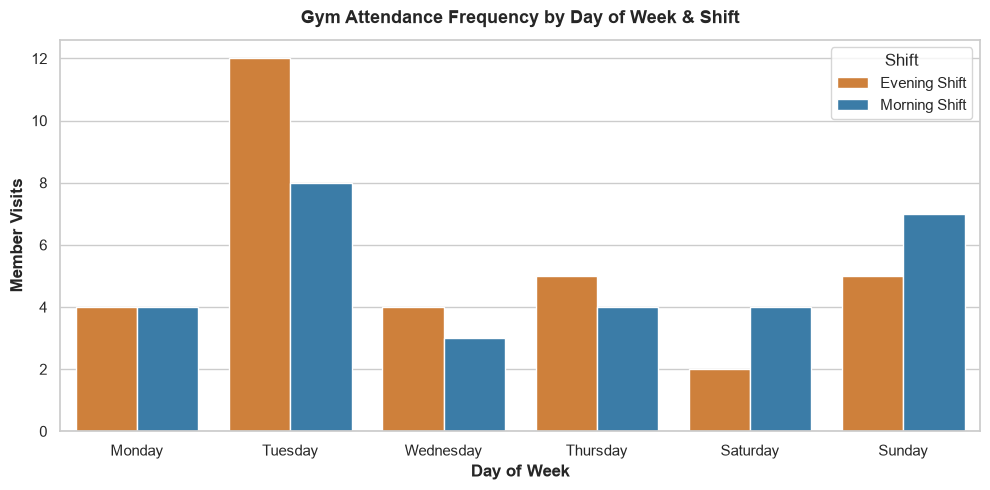

In [4]:
plt.figure(figsize=(10, 5))
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
counts = attendance_df.groupby(['day_of_week', 'time_slot']).size().reset_index(name='visit_count')

sns.barplot(
    data=counts,
    x='day_of_week',
    y='visit_count',
    hue='time_slot',
    order=[d for d in day_order if d in counts['day_of_week'].unique()],
    palette={'Morning Shift': '#2980b9', 'Evening Shift': '#e67e22'}
)
plt.title("Gym Attendance Frequency by Day of Week & Shift", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Day of Week", fontweight='bold')
plt.ylabel("Member Visits", fontweight='bold')
plt.legend(title="Shift")
plt.tight_layout()
plt.show()

### Visualization 2: Membership Plan Popularity vs Revenue Generation

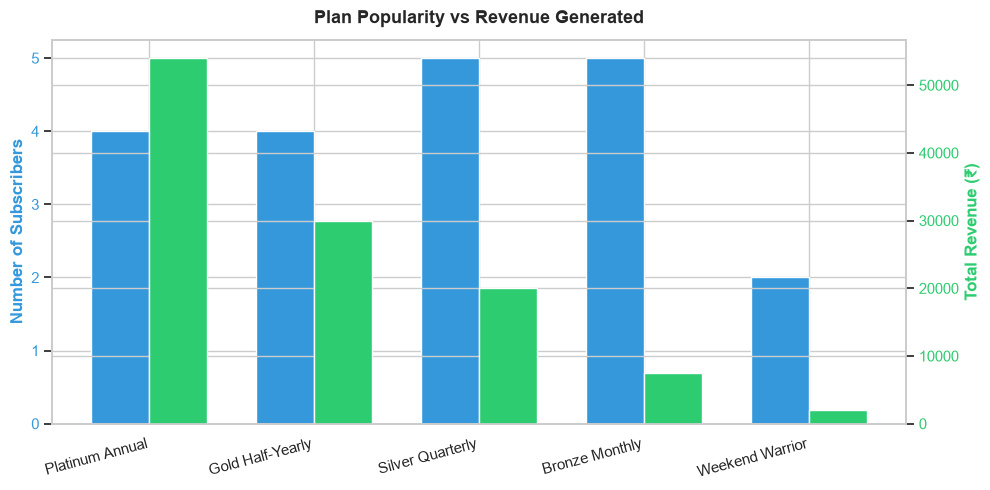

In [5]:
merged_plans = subscriptions_df.merge(plans_df, on='plan_id')
plan_summary = merged_plans.groupby('plan_name').agg(
    subscribers=('subscription_id', 'count'),
    total_revenue=('amount_paid', 'sum')
).reset_index().sort_values(by='total_revenue', ascending=False)

fig, ax1 = plt.subplots(figsize=(10, 5))
color1, color2 = '#3498db', '#2ecc71'
x = np.arange(len(plan_summary['plan_name']))
width = 0.35

ax1.bar(x - width/2, plan_summary['subscribers'], width, label='Total Subscribers', color=color1)
ax1.set_ylabel('Number of Subscribers', color=color1, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(plan_summary['plan_name'], rotation=15, ha='right')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
ax2.bar(x + width/2, plan_summary['total_revenue'], width, label='Revenue (₹)', color=color2)
ax2.set_ylabel('Total Revenue (₹)', color=color2, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("Plan Popularity vs Revenue Generated", fontsize=13, fontweight='bold', pad=12)
fig.tight_layout()
plt.show()

### Visualization 3: Trainer Client Workload

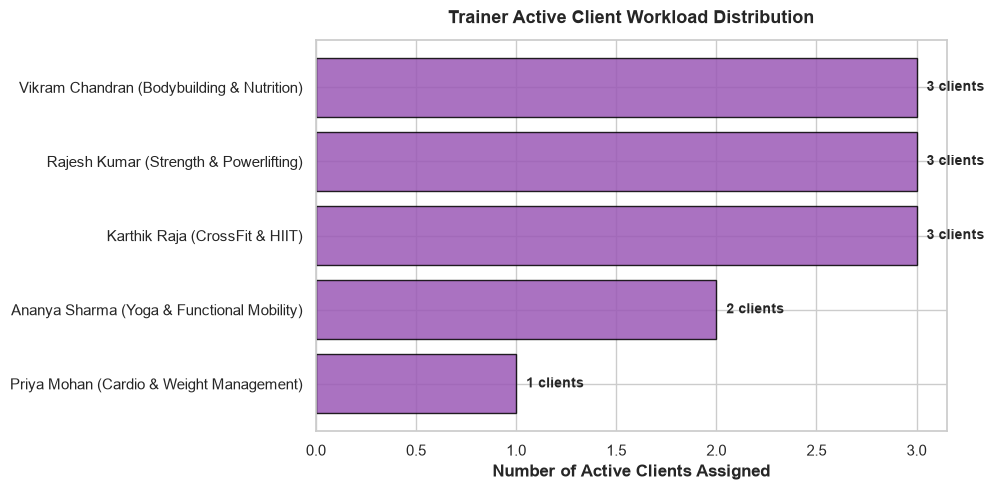

In [6]:
merged_trainers = trainers_df.merge(assignments_df[assignments_df['status'] == 'Active'], on='trainer_id', how='left')
workload = merged_trainers.groupby(['name', 'specialization']).size().reset_index(name='active_clients').sort_values('active_clients')
workload['label'] = workload['name'] + " (" + workload['specialization'] + ")"

plt.figure(figsize=(10, 5))
bars = plt.barh(workload['label'], workload['active_clients'], color='#9b59b6', edgecolor='black', alpha=0.85)
plt.xlabel("Number of Active Clients Assigned", fontweight='bold')
plt.title("Trainer Active Client Workload Distribution", fontsize=13, fontweight='bold', pad=12)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.05, bar.get_y() + bar.get_height()/2, f"{int(w)} clients", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

### Visualization 4: Workout Category Preference (Donut Chart)

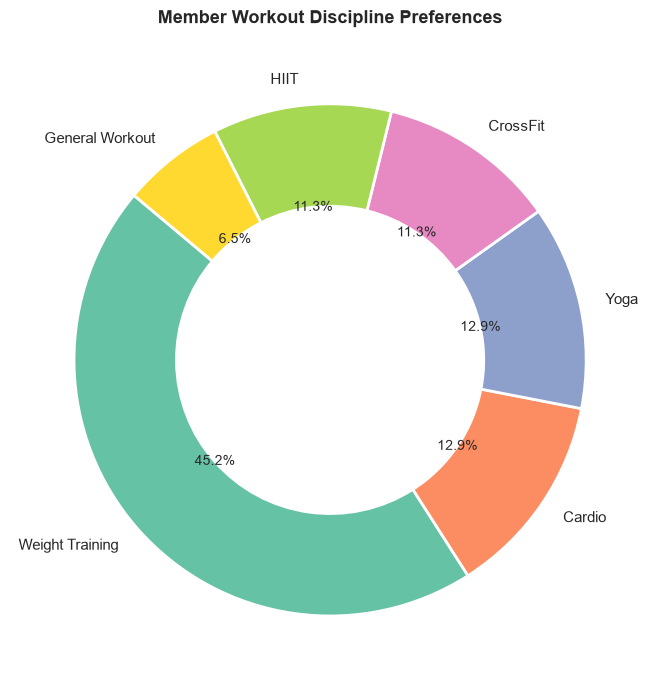

In [7]:
plt.figure(figsize=(7, 7))
workout_counts = attendance_df['workout_type'].value_counts()
colors = sns.color_palette("Set2", len(workout_counts))

plt.pie(
    workout_counts,
    labels=workout_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
plt.title("Member Workout Discipline Preferences", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### Visualization 5: Peak Traffic Heatmap (Hour vs Day)

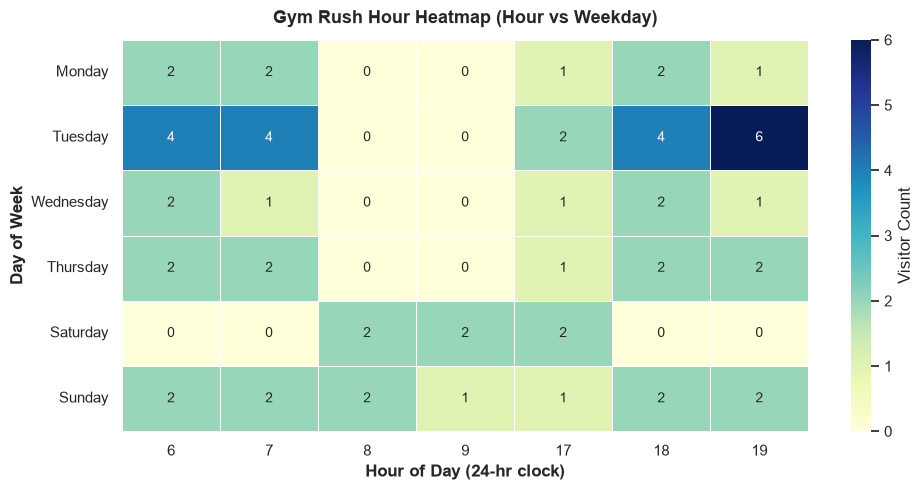

In [8]:
pivot = pd.crosstab(attendance_df['day_of_week'], attendance_df['check_in_hour'])
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot = pivot.reindex([d for d in day_order if d in pivot.index])

plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Visitor Count'}, linewidths=0.5)
plt.title("Gym Rush Hour Heatmap (Hour vs Weekday)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Hour of Day (24-hr clock)", fontweight='bold')
plt.ylabel("Day of Week", fontweight='bold')
plt.tight_layout()
plt.show()

### Visualization 6: Member Demographics & Age Analysis

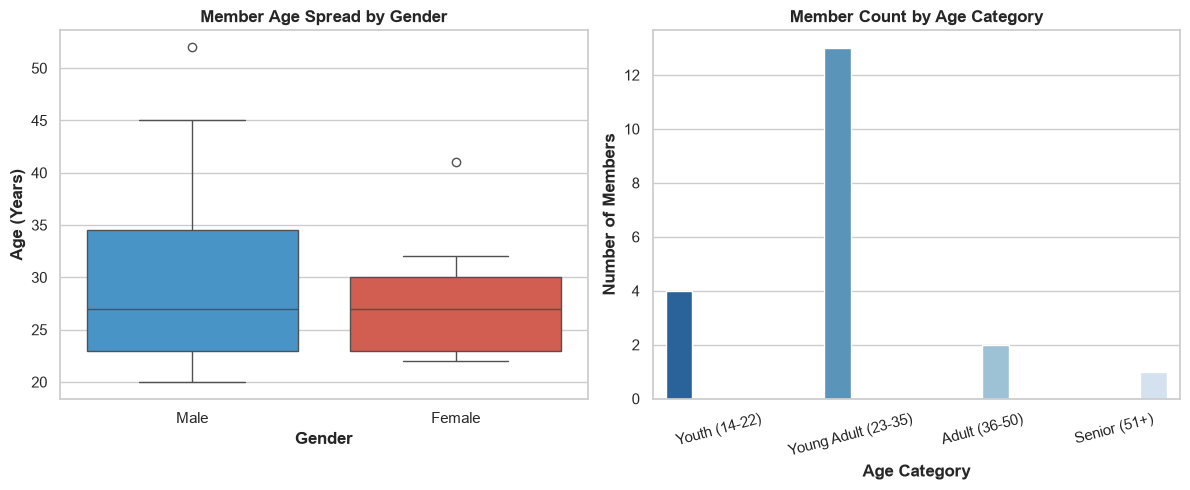

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=members_df, x='gender', y='age', hue='gender', legend=False, palette={'Male': '#3498db', 'Female': '#e74c3c'}, ax=axes[0])
axes[0].set_title("Member Age Spread by Gender", fontweight='bold')
axes[0].set_xlabel("Gender", fontweight='bold')
axes[0].set_ylabel("Age (Years)", fontweight='bold')

sns.countplot(data=members_df, x='age_group', hue='age_group', legend=False, palette='Blues_r', ax=axes[1])
axes[1].set_title("Member Count by Age Category", fontweight='bold')
axes[1].set_xlabel("Age Category", fontweight='bold')
axes[1].set_ylabel("Number of Members", fontweight='bold')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 6. Key Insights & Findings
1. **Peak Visiting Hours:** Prime attendance concentrates between 06:00–08:30 in the morning and 17:30–20:00 in the evening.
2. **Revenue Driver:** The *Platinum Annual* and *Gold Half-Yearly* plans generate the highest share of total revenue despite fewer subscribers than monthly/quarterly plans.
3. **Workout Preferences:** Weight Training and Cardio dominate over 60% of total member sessions, indicating high demand for gym floor space and free weights.
4. **Trainer Allocation:** Trainers Rajesh Kumar (Strength) and Vikram Chandran (Bodybuilding) handle the highest client load, suggesting demand for specialized strength coaching.